## Trade-off analysis

### This notebook performs a trade-off analysis of a grid-search exploring the effects of varying 3 hyperparameters used in a weighted least squares inversion of surface strain rates solving for slip deficit rates on faults and distributed moment rate sources in the crust

In [1]:
import os
import pandas as pd

# --- Paths for the self-contained supplement (run this notebook from Natgeo_supplements/Notebooks) ---
INPUT_DIR = "../Input_data/trade_off"
OUTPUT_DIR = "../output_data/trade_off_analysis"   # all CSV tables and figures written below
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load the trade-off surface data from a CSV file
trade_off_data = pd.read_csv(os.path.join(INPUT_DIR, "natgeo_tradeoff_surface_CALI_bodyforce_moment.csv"))
trade_off_data.head()

,weight_moment,weight_smooth,weight_bottom,chi2,var_reduction,Mo_on_fault_Nm_per_yr,Mo_off_fault_Nm_per_yr,Mo_total_Nm_per_yr,Pct_total_on_fault,Pct_total_off_fault,...,pct_strain_on_inpoly,pct_strain_off_inpoly,weight_rake,H_m,ndata,N_slip,M_moment,include_moment,backslip_top_seminorm2,backslip_mid_seminorm2
0,0.1,0.1,0.100000,0.282995,0.991673,1.610000e+19,1.970000e+19,3.580000e+19,45.015350,54.984650,...,0.455824,0.544176,5,15000,16512,5694,45690,1,0.028373,0.028443
1,0.1,0.1,0.166810,0.283002,0.991673,1.590000e+19,1.970000e+19,3.560000e+19,44.644877,55.355123,...,0.455673,0.544327,5,15000,16512,5694,45690,1,0.028327,0.028404
2,0.1,0.1,0.278256,0.283005,0.991673,1.580000e+19,1.970000e+19,3.550000e+19,44.470834,55.529166,...,0.455627,0.544373,5,15000,16512,5694,45690,1,0.028306,0.028386
3,0.1,0.1,0.464159,0.283006,0.991673,1.580000e+19,1.970000e+19,3.550000e+19,44.447454,55.552546,...,0.455792,0.544208,5,15000,16512,5694,45690,1,0.028292,0.028374
4,0.1,0.1,0.774264,0.283007,0.991673,1.580000e+19,1.970000e+19,3.550000e+19,44.495339,55.504661,...,0.456093,0.543907,5,15000,16512,5694,45690,1,0.028303,0.028387



3-D REGULARIZATION GRID
Models  = 1000
Columns = 47

Valid models = 1000 / 1000

STATISTICAL FILTER
|log10(chi2)| < 0.10
Reduced chi2 range = 0.794 -- 1.259
Models fitting data = 100 / 1000

PHYSICAL BOTTOM-DAMPING VALUES
0.27825594
0.46415888
0.77426368

Statistically acceptable = 100
Final physical + fitting = 30

[selection] SELECT_MODE = 'median'

REPRESENTATIVE MODEL
weight_moment = 2.15443
weight_smooth = 0.774264
weight_bottom = 0.464159
chi2          = 0.87096
log10(chi2)   = -0.0600

off-fault strain-rate (pct_strain_off_inpoly) (accepted ensemble):
  range           : 39.69 -- 50.09 %
  center +/- half : 44.89 +/- 5.20 %
  representative  : 44.33 %
  offset from center = 0.56 pct points (5.3% of range width)

Percentile rank of representative within accepted ensemble:
  on-fault moment rate                    :  43.3th percentile
  off-fault moment rate                   :  46.7th percentile
  pct_strain_off_inpoly                   :  46.7th percentile
  off-fault moment pa

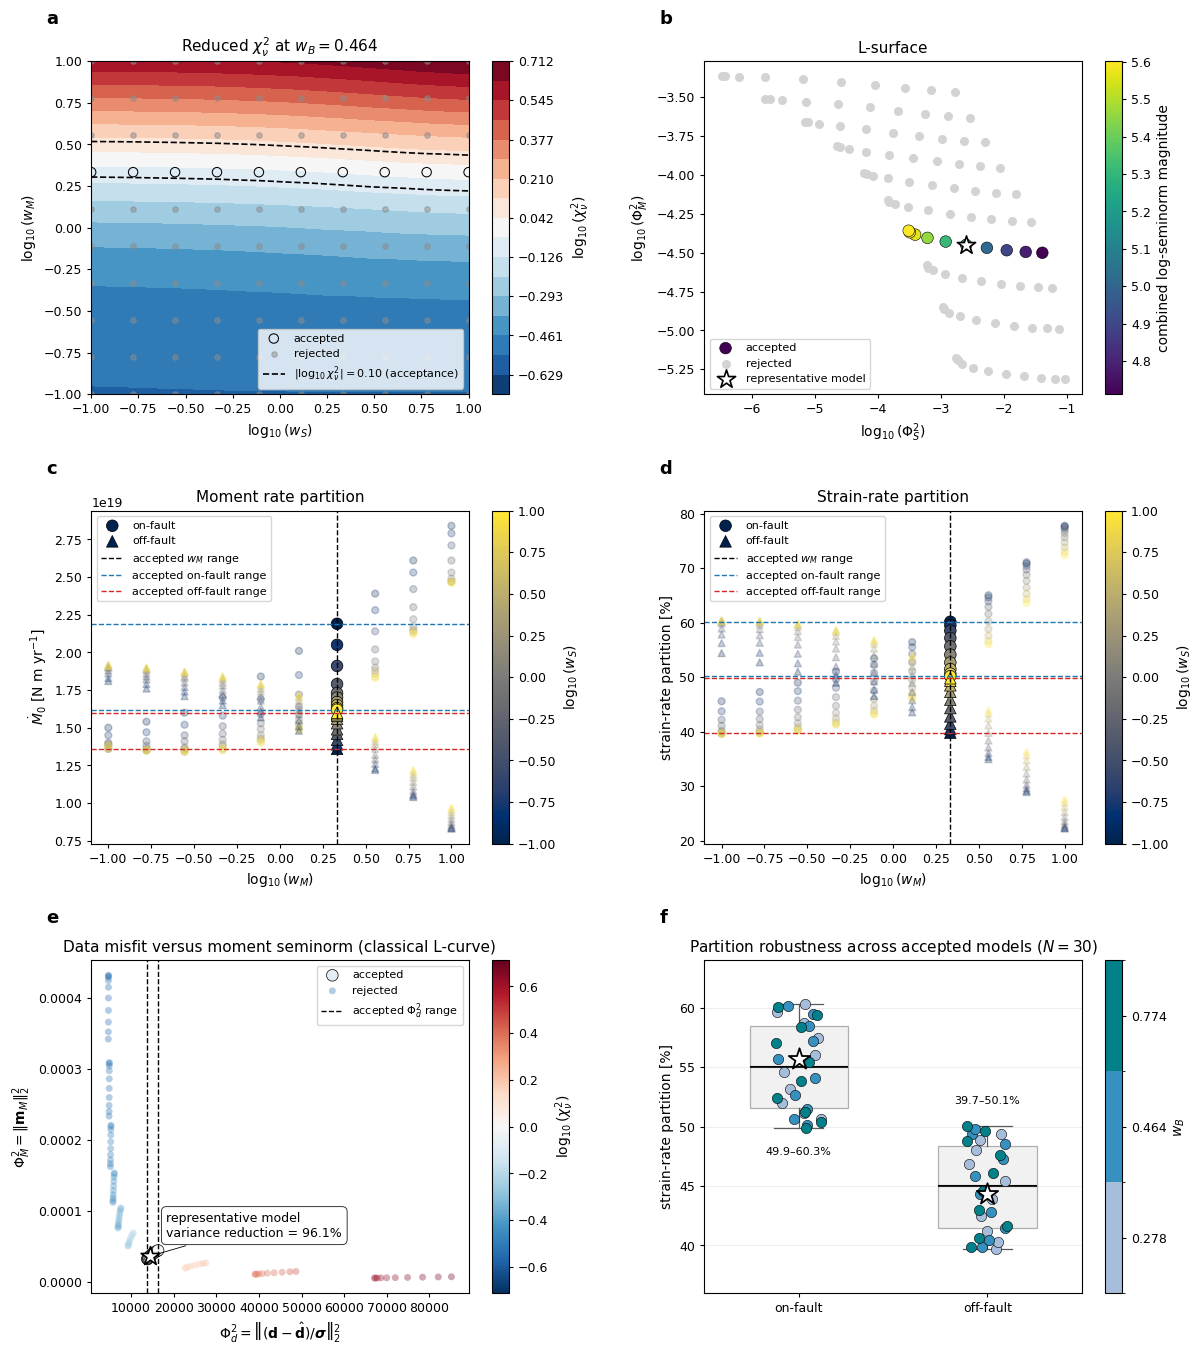


FINAL SUMMARY
Total grid models          : 1000
Statistically acceptable  : 100
Physical + fitting models : 30
Models on w_B slice       : 100
Accepted on w_B slice     : 10

Representative model (SELECT_MODE = 'median'):
  w_M = 2.15443
  w_S = 0.774264
  w_B = 0.464159
  chi2 = 0.8710

Representative in-polygon results:
  strain partition = 55.7% on / 44.3% off
  moment partition = 53.7% on / 46.3% off
  on-fault moment (slip-derived) = 1.730e+19 N m yr^-1
  off-fault moment (Savage-Simpson) = 1.490e+19 N m yr^-1

Headline off-fault strain-rate (pct_strain_off_inpoly) (center +/- half-range):
  44.9 +/- 5.2 %  (range 39.7--50.1 %)
  representative model: 44.3 %

BOUNDING MODELS (accepted ensemble)

Accepted-ensemble weight ranges:
  w_M : 2.15443 -- 2.15443
  w_S : 0.1 -- 10
  w_B : 0.278256 -- 0.774264

LOWER-BOUND model (minimum pct_strain_off_inpoly)
-------------------------------------------------
  w_M = 2.15443   w_S = 0.1   w_B = 0.278256
  chi2 = 0.8354   log10(chi2) = -0.0

In [2]:
# ======================================================================
# 3-D REGULARIZATION GRID SEARCH
#
# MODEL SELECTION + ORIGINAL-STYLE 6-PANEL FIGURE
# ======================================================================
#
# REGULARIZATION PARAMETERS
#   w_M = weight_moment
#   w_S = weight_smooth
#   w_B = weight_bottom
#
# STATISTICAL ACCEPTANCE
#   |log10(chi^2)| < CHI2_LOG_TOL   (0.10 -> 0.79 <= chi^2 <= 1.26)
#
# PHYSICAL BOTTOM-DAMPING VALUES
#   w_B = 0.27825594, 0.46415888, 0.77426368
#
# FINAL ACCEPTED ENSEMBLE
#   statistically acceptable AND physical w_B
#
# REPRESENTATIVE MODEL (default SELECT_MODE = "midrange_offfault")
#   The accepted model whose off-fault MOMENT-RATE fraction
#   (CSV column SELECT_COLUMN, default "Pct_total_off_fault") is closest
#   to the CENTER of the accepted range, (min + max)/2. Ties within 0.5
#   percentage points are broken by chi^2 closest to 1.
#   The lower- and upper-bound models are defined by the SAME quantity.
#   The representative model is for display only; reported uncertainties
#   are the range spanned by the lower- and upper-bound models.
#
# NOTATION
#   Phi_d^2 = || (d - d_hat) / sigma ||_2^2      weighted data misfit
#   Phi_M^2 = || m_M ||_2^2                      moment seminorm
#   Phi_S^2 = || P_smooth m_s ||_2^2             slip-smoothing seminorm
#             (+ perpendicular-rake term when variable rake is used)
#   Phi_B^2 = || m_s,bottom ||_2^2               bottom-row seminorm
#
# FIGURE: six-panel trade-off figure
#   Panels a-e : fixed at representative w_B
#   Panel f    : full final accepted 3-D ensemble
# ======================================================================


# ======================================================================
# 0. IMPORTS
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
from scipy.interpolate import griddata
from scipy.stats import spearmanr


# ======================================================================
# 1. USER SETTINGS
# ======================================================================

INPUT_DIR = "../Input_data/trade_off"
OUTPUT_DIR = "../output_data/trade_off_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)
CSV = os.path.join(INPUT_DIR, "natgeo_tradeoff_surface_CALI_bodyforce_moment.csv")

# Statistical acceptance
CHI2_LOG_TOL = 0.10

# Exact 10-point grid
GRID_WEIGHTS = np.logspace(-1, 1, 10)

# Physical bottom-damping values
PHYSICAL_WB_VALUES = GRID_WEIGHTS[2:5]

# ----------------------------------------------------------------------
# Representative-model selection rule
# ----------------------------------------------------------------------
#   "midrange_offfault" : accepted model whose off-fault strain fraction is
#                         closest to the center of the accepted range,
#                         (min + max)/2; ties within MIDRANGE_TIE_PCT
#                         percentage points broken by chi^2 closest to 1.
#                         Consistent with range-based uncertainties. (default)
#
#   "median"            : tested model nearest the component-wise median of
#                         the accepted ensemble in log-weight space.
#   "min_moment"        : minimum moment seminorm     Phi_M^2
#   "min_backslip"      : minimum slip-smoothing norm Phi_S^2
#   "min_bottom"        : minimum bottom-row norm     Phi_B^2
#   "min_total"         : minimum joint log-distance from the achievable
#                         (moment, backslip) minima
#
# The min_* modes generally land on a grid boundary; use them only for
# supplementary sensitivity comparisons.
SELECT_MODE = "median"

# Tie-break window for "midrange_offfault" [percentage points]
MIDRANGE_TIE_PCT = 0.5

# Headline quantity used for the representative model AND the bounding
# models. Must be an off-fault percentage column of the sweep CSV.
#   "Pct_total_off_fault" : off-fault MOMENT-RATE fraction, GLOBAL domain,
#                           double-couple off-fault moment (MATLAB col 10)
# Other options from the same CSV:
#   "pct_off_inpoly"      : moment-rate fraction, in-polygon, double-couple
#   "pct_off_ss_inpoly"   : moment-rate fraction, in-polygon, Savage-Simpson
#   "pct_strain_off_inpoly": STRAIN-rate fraction, in-polygon
#   "pct_strain_on_inpoly": STRAIN-rate fraction, in-polygon
SELECT_COLUMN = "pct_strain_off_inpoly"
SELECT_LABEL = "off-fault strain-rate (pct_strain_off_inpoly)"

# Output
SAVE_FIGURES = True
SAVE_TABLES = True
DPI = 600

# Mode-tagged so different SELECT_MODE runs do not overwrite each other.
# For "median" the suffix is empty (original filenames kept).
_MODE_SUFFIX = "" if SELECT_MODE == "median" else f"_{SELECT_MODE}"

FIG6_PNG = os.path.join(OUTPUT_DIR, f"Fig_tradeoff_6panel{_MODE_SUFFIX}.png")
FIG6_PDF = os.path.join(OUTPUT_DIR, f"Fig_tradeoff_6panel{_MODE_SUFFIX}.pdf")
REP_CSV = os.path.join(OUTPUT_DIR, f"representative_model{_MODE_SUFFIX}.csv")


# ======================================================================
# 2. MATHEMATICAL LABELS
# ======================================================================

LAB_WM = r"$\log_{10}(w_M)$"
LAB_WS = r"$\log_{10}(w_S)$"
LAB_WB = r"$\log_{10}(w_B)$"
LAB_CHI2 = r"$\log_{10}(\chi_\nu^2)$"
LAB_PHI_D = r"$\log_{10}(\Phi_d^2)$"
LAB_PHI_M = r"$\log_{10}(\Phi_M^2)$"
LAB_PHI_S = r"$\log_{10}(\Phi_S^2)$"
LAB_PHI_B = r"$\log_{10}(\Phi_B^2)$"


# ======================================================================
# 3. PLOT STYLE
# ======================================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ======================================================================
# 4. HELPERS
# ======================================================================

def safe_log10(x):
    x = np.asarray(x, dtype=float)
    out = np.full(x.shape, np.nan)
    use = np.isfinite(x) & (x > 0)
    out[use] = np.log10(x[use])
    return out


def representative_star(ax, x, y, label=None, size=190):
    ax.scatter(x, y, s=size, c="white", marker="*", edgecolors="k",
               linewidth=1.2, label=label, zorder=20)


def print_range(name, values, mask, representative_index, unit="", fmt=".4g"):
    values = np.asarray(values, dtype=float)
    x = values[mask & np.isfinite(values)]

    if len(x) == 0:
        print(f"\n{name}: no finite values")
        return None

    p05, p25, med, p75, p95 = np.percentile(x, [5, 25, 50, 75, 95])
    rep = values[representative_index]

    print(f"\n{name}")
    print("-" * len(name))
    print(f"  full range      : {x.min():{fmt}} -- {x.max():{fmt}} {unit}")
    print(f"  5--95%          : {p05:{fmt}} -- {p95:{fmt}} {unit}")
    print(f"  25--75%         : {p25:{fmt}} -- {p75:{fmt}} {unit}")
    print(f"  median          : {med:{fmt}} {unit}")
    print(f"  representative  : {rep:{fmt}} {unit}")

    return {
        "N": len(x),
        "min": np.min(x),
        "p05": p05,
        "p25": p25,
        "median": med,
        "p75": p75,
        "p95": p95,
        "max": np.max(x),
        "representative": rep,
    }


def report_spearman(xname, x, yname, y, mask):
    use = mask & np.isfinite(x) & np.isfinite(y)
    xx = np.asarray(x[use], dtype=float)
    yy = np.asarray(y[use], dtype=float)

    if len(xx) < 3:
        print(f"{xname:16s} -> {yname:22s}: insufficient models")
        return
    if np.ptp(xx) < 1e-12:
        print(f"{xname:16s} -> {yname:22s}: not defined (parameter constant)")
        return
    if np.ptp(yy) < 1e-12:
        print(f"{xname:16s} -> {yname:22s}: not defined (output constant)")
        return

    rho, p = spearmanr(xx, yy)
    print(f"{xname:16s} -> {yname:22s}: rho={rho:+.3f}, p={p:.3g}")


def _dash(color, ls="--", lw=1.0):
    """Proxy legend handle for dashed / dotted reference lines."""
    return Line2D([0], [0], color=color, ls=ls, lw=lw)


# ======================================================================
# 5. LOAD CSV
# ======================================================================

T = pd.read_csv(CSV)

print("\n" + "=" * 80)
print("3-D REGULARIZATION GRID")
print("=" * 80)
print(f"Models  = {len(T)}")
print(f"Columns = {len(T.columns)}")


# ======================================================================
# 6. REQUIRED COLUMNS
# ======================================================================

required_columns = [
    "weight_moment",
    "weight_smooth",
    "weight_bottom",
    "chi2",
    "var_reduction",
    "misfit2_weighted",
    "moment_seminorm2",
    "backslip_seminorm2",
    "backslip_bottom_seminorm2",
    "Mo_on_fault_inpoly_Nm_per_yr",
    "Mo_off_ss_inpoly_Nm_per_yr",
    "pct_strain_on_inpoly",
    "pct_strain_off_inpoly",
]

if SELECT_COLUMN not in required_columns:
    required_columns.append(SELECT_COLUMN)

missing = [col for col in required_columns if col not in T.columns]

if missing:
    raise KeyError("Missing required columns:\n\n" + "\n".join(missing))


# ======================================================================
# 7. EXTRACT VARIABLES
# ======================================================================

# Regularization weights
wm = T["weight_moment"].to_numpy(float)
ws = T["weight_smooth"].to_numpy(float)
wb = T["weight_bottom"].to_numpy(float)

# Fit
chi2 = T["chi2"].to_numpy(float)
var_red = T["var_reduction"].to_numpy(float)
misfit2 = T["misfit2_weighted"].to_numpy(float)

# Regularization diagnostics
mom_norm2 = T["moment_seminorm2"].to_numpy(float)
bs_norm2 = T["backslip_seminorm2"].to_numpy(float)
bottom_norm2 = T["backslip_bottom_seminorm2"].to_numpy(float)

# In-polygon moment
mo_on = T["Mo_on_fault_inpoly_Nm_per_yr"].to_numpy(float)
mo_off = T["Mo_off_ss_inpoly_Nm_per_yr"].to_numpy(float)
mo_total = mo_on + mo_off

moment_pct_on = np.divide(
    100.0 * mo_on,
    mo_total,
    out=np.full_like(mo_total, np.nan),
    where=(mo_total != 0),
)
moment_pct_off = 100.0 - moment_pct_on

# In-polygon strain partition (accept fractions or percentages)
pct_on_raw = T["pct_strain_on_inpoly"].to_numpy(float)
pct_off_raw = T["pct_strain_off_inpoly"].to_numpy(float)

if np.nanmax(np.abs(np.concatenate([pct_on_raw, pct_off_raw]))) <= 1.5:
    pct_on = 100.0 * pct_on_raw
    pct_off = 100.0 * pct_off_raw
else:
    pct_on = pct_on_raw.copy()
    pct_off = pct_off_raw.copy()


# Headline quantity for representative + bounding models (percent)
sel_raw = T[SELECT_COLUMN].to_numpy(float)
sel_pct = 100.0 * sel_raw if np.nanmax(np.abs(sel_raw)) <= 1.5 else sel_raw.copy()


# ======================================================================
# 8. QUALITY CONTROL
# ======================================================================

valid = (
    np.isfinite(wm)
    & np.isfinite(ws)
    & np.isfinite(wb)
    & np.isfinite(chi2)
    & np.isfinite(mo_on)
    & np.isfinite(mo_off)
    & np.isfinite(pct_on)
    & np.isfinite(pct_off)
    & np.isfinite(sel_pct)
    & (wm > 0)
    & (ws > 0)
    & (wb > 0)
    & (chi2 > 0)
)

print(f"\nValid models = {valid.sum()} / {len(T)}")


# ======================================================================
# 9. LOG VARIABLES
# ======================================================================

log_wm = safe_log10(wm)
log_ws = safe_log10(ws)
log_wb = safe_log10(wb)
log_chi2 = safe_log10(chi2)

log_phi_d2 = safe_log10(misfit2)        # norm((d-dhat)./Esig,2)^2
log_phi_M2 = safe_log10(mom_norm2)      # norm(mhat_mom,2)^2
log_phi_S2 = safe_log10(bs_norm2)       # norm(pm_smooth*m_par,2)^2 (+ perp)
log_phi_B2 = safe_log10(bottom_norm2)   # norm(m_par(bottom_idx),2)^2


# ======================================================================
# 10. STATISTICAL ACCEPTANCE
# ======================================================================

good_fit = valid & (np.abs(log_chi2) < CHI2_LOG_TOL)

chi2_lo = 10**(-CHI2_LOG_TOL)
chi2_hi = 10**(+CHI2_LOG_TOL)

print("\n" + "=" * 80)
print("STATISTICAL FILTER")
print("=" * 80)
print(f"|log10(chi2)| < {CHI2_LOG_TOL:.2f}")
print(f"Reduced chi2 range = {chi2_lo:.3f} -- {chi2_hi:.3f}")
print(f"Models fitting data = {good_fit.sum()} / {valid.sum()}")


# ======================================================================
# 11. PHYSICAL BOTTOM-DAMPING FILTER
# ======================================================================

physical_bottom = np.zeros(len(T), dtype=bool)

for allowed in PHYSICAL_WB_VALUES:
    physical_bottom |= np.isclose(wb, allowed, rtol=1e-7, atol=1e-12)

print("\n" + "=" * 80)
print("PHYSICAL BOTTOM-DAMPING VALUES")
print("=" * 80)
for value in PHYSICAL_WB_VALUES:
    print(f"{value:.8f}")


# ======================================================================
# 12. FINAL ACCEPTED ENSEMBLE
# ======================================================================

accepted_3d = good_fit & physical_bottom

if accepted_3d.sum() == 0:
    raise RuntimeError(
        "No models satisfy both the statistical and physical criteria."
    )

print(f"\nStatistically acceptable = {good_fit.sum()}")
print(f"Final physical + fitting = {accepted_3d.sum()}")


# ======================================================================
# 13. MEDIAN OF FINAL ACCEPTED ENSEMBLE (log-weight space)
# ======================================================================

median_log_wm = np.median(log_wm[accepted_3d])
median_log_ws = np.median(log_ws[accepted_3d])
median_log_wb = np.median(log_wb[accepted_3d])


# ======================================================================
# 14. REPRESENTATIVE MODEL
# ======================================================================

distance = np.sqrt(
    (log_wm - median_log_wm)**2
    + (log_ws - median_log_ws)**2
    + (log_wb - median_log_wb)**2
)

eligible_distance = np.where(accepted_3d, distance, np.inf)


def _mask_to_accepted(values):
    """Return `values` with rejected models set to +inf (for argmin)."""
    v = np.asarray(values, dtype=float)
    return np.where(accepted_3d & np.isfinite(v), v, np.inf)


# Midrange of the headline quantity (always computed so it can be
# reported whatever SELECT_MODE is used).
sel_acc_min = np.min(sel_pct[accepted_3d])
sel_acc_max = np.max(sel_pct[accepted_3d])
sel_mid = 0.5 * (sel_acc_min + sel_acc_max)
sel_halfrange = 0.5 * (sel_acc_max - sel_acc_min)
dist_to_mid = np.abs(sel_pct - sel_mid)


if SELECT_MODE == "midrange_offfault":

    # Accepted model closest to the center of the accepted range of the
    # headline quantity (SELECT_COLUMN).
    # Among models within MIDRANGE_TIE_PCT percentage points of the closest
    # one, prefer the best fit (chi^2 closest to 1).
    _closest = np.min(dist_to_mid[accepted_3d])
    _near = accepted_3d & (dist_to_mid <= _closest + MIDRANGE_TIE_PCT)
    criterion = np.where(_near, np.abs(log_chi2), np.inf)

elif SELECT_MODE == "median":

    criterion = eligible_distance

elif SELECT_MODE == "min_moment":

    criterion = _mask_to_accepted(mom_norm2)

elif SELECT_MODE == "min_backslip":

    criterion = _mask_to_accepted(bs_norm2)

elif SELECT_MODE == "min_bottom":

    criterion = _mask_to_accepted(bottom_norm2)

elif SELECT_MODE == "min_total":

    _lm = np.log10(np.where(mom_norm2 > 0, mom_norm2, np.nan))
    _lb = np.log10(np.where(bs_norm2 > 0, bs_norm2, np.nan))
    _lm_min = np.nanmin(_lm[accepted_3d])
    _lb_min = np.nanmin(_lb[accepted_3d])
    _joint = np.sqrt((_lm - _lm_min)**2 + (_lb - _lb_min)**2)
    criterion = _mask_to_accepted(_joint)

else:

    raise ValueError(
        f"Unknown SELECT_MODE = {SELECT_MODE!r}. "
        "Use one of: 'midrange_offfault', 'median', 'min_moment', "
        "'min_backslip', 'min_bottom', 'min_total'."
    )


best_idx = int(np.argmin(criterion))

print(f"\n[selection] SELECT_MODE = {SELECT_MODE!r}")

best_wm = wm[best_idx]
best_ws = ws[best_idx]
best_wb = wb[best_idx]

print("\n" + "=" * 80)
print("REPRESENTATIVE MODEL")
print("=" * 80)
print(f"weight_moment = {best_wm:.6g}")
print(f"weight_smooth = {best_ws:.6g}")
print(f"weight_bottom = {best_wb:.6g}")
print(f"chi2          = {chi2[best_idx]:.5f}")
print(f"log10(chi2)   = {log_chi2[best_idx]:+.4f}")

# Centering diagnostic: how far the displayed model is from the center of
# the accepted off-fault range, as a fraction of the full range width.
_range_width = sel_acc_max - sel_acc_min
_offset_frac = (dist_to_mid[best_idx] / _range_width) if _range_width > 0 else 0.0

print(f"\n{SELECT_LABEL} (accepted ensemble):")
print(f"  range           : {sel_acc_min:.2f} -- {sel_acc_max:.2f} %")
print(f"  center +/- half : {sel_mid:.2f} +/- {sel_halfrange:.2f} %")
print(f"  representative  : {sel_pct[best_idx]:.2f} %")
print(f"  offset from center = {dist_to_mid[best_idx]:.2f} pct points "
      f"({100*_offset_frac:.1f}% of range width)")

if _offset_frac > 0.10:
    print("  NOTE: no accepted model lies close to the center of the range; "
          "say in the caption that the displayed model is the one closest "
          "to the center.")

# Where the representative falls in the ensemble for other quantities.
print("\nPercentile rank of representative within accepted ensemble:")
for _name, _vals in [
    ("on-fault moment rate", mo_on),
    ("off-fault moment rate", mo_off),
    (f"{SELECT_COLUMN}", sel_pct),
    ("off-fault moment partition (SS, inpoly)", moment_pct_off),
    ("off-fault strain partition", pct_off),
]:
    _acc = _vals[accepted_3d]
    _rank = 100.0 * np.mean(_acc <= _vals[best_idx])
    print(f"  {_name:40s}: {_rank:5.1f}th percentile")


# ======================================================================
# 15. SAVE SELECTION TO TABLE
# ======================================================================

T["valid"] = valid
T["acceptable_fit"] = good_fit
T["physical_bottom"] = physical_bottom
T["accepted"] = accepted_3d
T["distance_to_accepted_median"] = distance
T[f"dist_to_midrange_{SELECT_COLUMN}"] = dist_to_mid
T["representative"] = np.arange(len(T)) == best_idx


# ======================================================================
# 16. SCIENTIFIC RANGES
# ======================================================================

print("\n" + "=" * 80)
print("FINAL ACCEPTED-ENSEMBLE RESULTS")
print("=" * 80)

summary_rows = []

for key, name, values, unit, fmt in [
    ("strain_on", "On-fault strain-rate partition", pct_on, "%", ".2f"),
    ("strain_off", "Off-fault strain-rate partition", pct_off, "%", ".2f"),
    ("Mo_on", "On-fault moment rate (slip-derived)", mo_on, "N m yr^-1", ".3e"),
    ("Mo_off", "Off-fault moment rate (Savage-Simpson)", mo_off, "N m yr^-1", ".3e"),
    ("moment_on", "On-fault moment-rate partition", moment_pct_on, "%", ".2f"),
    ("moment_off", "Off-fault moment-rate partition", moment_pct_off, "%", ".2f"),
    ("headline", f"Headline: {SELECT_LABEL}", sel_pct, "%", ".2f"),
]:
    stats = print_range(name, values, accepted_3d, best_idx, unit, fmt)
    if stats is not None:
        stats["quantity"] = key
        summary_rows.append(stats)


# ======================================================================
# 17. SAVE TABLES
# ======================================================================

if SAVE_TABLES:
    T.loc[accepted_3d].to_csv(os.path.join(OUTPUT_DIR, "accepted_model_ensemble.csv"), index=False)
    T.iloc[[best_idx]].to_csv(REP_CSV, index=False)
    pd.DataFrame(summary_rows).to_csv(os.path.join(OUTPUT_DIR, "accepted_ensemble_summary.csv"), index=False)


# ======================================================================
# 18. REPRESENTATIVE w_bottom SLICE FOR SIX-PANEL FIGURE
# ======================================================================

slice_mask = valid & np.isclose(wb, best_wb, rtol=1e-8, atol=1e-12)
accept_slice = slice_mask & good_fit
reject_slice = slice_mask & ~good_fit

if accept_slice.sum() == 0:
    raise RuntimeError(
        "No statistically acceptable models on representative w_B slice."
    )


# ======================================================================
# 19. L-SURFACE DIAGNOSTIC SCORE
# ======================================================================

phi_M2_min = np.nanmin(log_phi_M2[accept_slice])
phi_S2_min = np.nanmin(log_phi_S2[accept_slice])

d_M = log_phi_M2 - phi_M2_min
d_S = log_phi_S2 - phi_S2_min

score = np.sqrt(d_M**2 + d_S**2)


# ======================================================================
# 20. CHI2 SURFACE ON REPRESENTATIVE w_B SLICE
# ======================================================================

xi = np.linspace(np.nanmin(log_ws[slice_mask]), np.nanmax(log_ws[slice_mask]), 180)
yi = np.linspace(np.nanmin(log_wm[slice_mask]), np.nanmax(log_wm[slice_mask]), 180)

Xi, Yi = np.meshgrid(xi, yi)

Zi_chi = griddata(
    (log_ws[slice_mask], log_wm[slice_mask]),
    log_chi2[slice_mask],
    (Xi, Yi),
    method="linear",
)

log_chi2_abs_max = np.nanmax(np.abs(log_chi2[slice_mask]))


# ======================================================================
# FIGURE: SIX-PANEL TRADE-OFF / ROBUSTNESS FIGURE
#
# a  Reduced chi2 surface
# b  L-surface
# c  In-polygon moment-rate path
# d  In-polygon strain-rate partition
# e  Classical L-curve
# f  Final-ensemble strain-partition robustness
#
# Panels a-e use representative w_B slice.
# Panel f uses the FULL final accepted 3-D ensemble.
# ======================================================================

fig, axes = plt.subplots(3, 2, figsize=(14, 16))
plt.subplots_adjust(wspace=0.30, hspace=0.35)
axes = axes.ravel()


# ======================================================================
# PANEL A -- REDUCED CHI2 SURFACE
# ======================================================================

levels_chi = np.linspace(-log_chi2_abs_max, +log_chi2_abs_max, 18)

cf1 = axes[0].contourf(
    Xi, Yi, Zi_chi,
    levels=levels_chi,
    cmap="RdBu_r",
    vmin=-log_chi2_abs_max,
    vmax=+log_chi2_abs_max,
)

# Statistical acceptance contours
try:
    axes[0].contour(
        Xi, Yi, Zi_chi,
        levels=[-CHI2_LOG_TOL, +CHI2_LOG_TOL],
        colors="k",
        linewidths=1.2,
        linestyles="--",
    )
except ValueError:
    pass

# Rejected
axes[0].scatter(
    log_ws[reject_slice], log_wm[reject_slice],
    s=15, c="0.55", alpha=0.50, label="rejected",
)

# Accepted on this w_B slice
axes[0].scatter(
    log_ws[accept_slice], log_wm[accept_slice],
    s=46, facecolors="none", edgecolors="k", linewidth=0.75, label="accepted",
)

axes[0].set_xlabel(LAB_WS)
axes[0].set_ylabel(LAB_WM)
axes[0].set_title(rf"Reduced $\chi_\nu^2$ at $w_B={best_wb:.3g}$")

cb1 = fig.colorbar(cf1, ax=axes[0])
cb1.set_label(LAB_CHI2)

handles, labels = axes[0].get_legend_handles_labels()
legend_dict = dict(zip(labels, handles))

axes[0].legend(
    [legend_dict["accepted"], legend_dict["rejected"], _dash("k", "--", 1.2)],
    ["accepted", "rejected",
     rf"$|\log_{{10}}\chi_\nu^2|={CHI2_LOG_TOL:.2f}$ (acceptance)"],
    loc="lower right",
    fontsize=8,
)


# ======================================================================
# PANEL B
# L-SURFACE
#
# x = log10(Phi_S^2)
# y = log10(Phi_M^2)
# color = combined seminorm magnitude in log space
# ======================================================================
combined_seminorm = np.sqrt(
    log_phi_M2**2
    + log_phi_S2**2
)

axes[1].scatter(
    log_phi_S2[
        reject_slice
    ],
    log_phi_M2[
        reject_slice
    ],
    s=30,
    c="lightgray",
    label="rejected",
)

sc2 = axes[1].scatter(
    log_phi_S2[
        accept_slice
    ],
    log_phi_M2[
        accept_slice
    ],
    c=combined_seminorm[
        accept_slice
    ],
    s=70,
    cmap="viridis",
    edgecolor="k",
    linewidth=0.4,
    label="accepted",
)

# Representative model
representative_star(
    axes[1],
    log_phi_S2[
        best_idx
    ],
    log_phi_M2[
        best_idx
    ],
    label="representative model",
)

axes[1].set_xlabel(
    LAB_PHI_S
)

axes[1].set_ylabel(
    LAB_PHI_M
)

axes[1].set_title(
    "L-surface"
)

cb2 = fig.colorbar(
    sc2,
    ax=axes[1],
)

cb2.set_label(
    r"combined log-seminorm magnitude"
)

handles, labels = axes[1].get_legend_handles_labels()

legend_dict = dict(
    zip(
        labels,
        handles,
    )
)

axes[1].legend(
    [
        legend_dict["accepted"],
        legend_dict["rejected"],
        legend_dict["representative model"],
    ],
    [
        "accepted",
        "rejected",
        "representative model",
    ],
    loc="best",
    fontsize=8,
)

# ======================================================================
# PANEL C -- IN-POLYGON MOMENT-RATE PATH
# ======================================================================

# Rejected on-fault / off-fault
axes[2].scatter(
    log_wm[reject_slice], mo_on[reject_slice], c=log_ws[reject_slice],
    s=25, cmap="cividis", vmin=-1, vmax=1, alpha=0.25, marker="o",
)
axes[2].scatter(
    log_wm[reject_slice], mo_off[reject_slice], c=log_ws[reject_slice],
    s=25, cmap="cividis", vmin=-1, vmax=1, alpha=0.25, marker="^",
)

# Accepted on-fault / off-fault
sc3 = axes[2].scatter(
    log_wm[accept_slice], mo_on[accept_slice], c=log_ws[accept_slice],
    s=70, cmap="cividis", vmin=-1, vmax=1,
    edgecolor="k", linewidth=0.5, marker="o", label="on-fault",
)
axes[2].scatter(
    log_wm[accept_slice], mo_off[accept_slice], c=log_ws[accept_slice],
    s=70, cmap="cividis", vmin=-1, vmax=1,
    edgecolor="k", linewidth=0.5, marker="^", label="off-fault",
)

# Accepted moment-weight bounds
log_wm_lo = np.nanmin(log_wm[accept_slice])
log_wm_hi = np.nanmax(log_wm[accept_slice])

axes[2].axvline(log_wm_lo, color="k", ls="--", lw=1.0)
if not np.isclose(log_wm_lo, log_wm_hi):
    axes[2].axvline(log_wm_hi, color="k", ls="--", lw=1.0)

# Accepted output ranges
axes[2].axhline(np.nanmin(mo_on[accept_slice]), color="C0", ls="--", lw=1.0)
axes[2].axhline(np.nanmax(mo_on[accept_slice]), color="C0", ls="--", lw=1.0)
axes[2].axhline(np.nanmin(mo_off[accept_slice]), color="C3", ls="--", lw=1.0)
axes[2].axhline(np.nanmax(mo_off[accept_slice]), color="C3", ls="--", lw=1.0)

axes[2].set_xlabel(LAB_WM)
axes[2].set_ylabel(r"$\dot{M}_0$ [N m yr$^{-1}$]")
axes[2].set_title("Moment rate partition")

cb3 = fig.colorbar(sc3, ax=axes[2])
cb3.set_label(LAB_WS)

_h2, _l2 = axes[2].get_legend_handles_labels()
axes[2].legend(
    _h2 + [_dash("k", "--", 1.0), _dash("C0", "--", 1.0), _dash("C3", "--", 1.0)],
    _l2 + [r"accepted $w_M$ range", "accepted on-fault range",
           "accepted off-fault range"],
    loc="best",
    fontsize=8,
)


# ======================================================================
# PANEL D -- IN-POLYGON STRAIN-RATE PARTITION
# ======================================================================

# Rejected
axes[3].scatter(
    log_wm[reject_slice], pct_on[reject_slice], c=log_ws[reject_slice],
    s=25, cmap="cividis", vmin=-1, vmax=1, alpha=0.25, marker="o",
)
axes[3].scatter(
    log_wm[reject_slice], pct_off[reject_slice], c=log_ws[reject_slice],
    s=25, cmap="cividis", vmin=-1, vmax=1, alpha=0.25, marker="^",
)

# Accepted
sc4 = axes[3].scatter(
    log_wm[accept_slice], pct_on[accept_slice], c=log_ws[accept_slice],
    s=70, cmap="cividis", vmin=-1, vmax=1,
    edgecolor="k", linewidth=0.5, marker="o", label="on-fault",
)
axes[3].scatter(
    log_wm[accept_slice], pct_off[accept_slice], c=log_ws[accept_slice],
    s=70, cmap="cividis", vmin=-1, vmax=1,
    edgecolor="k", linewidth=0.5, marker="^", label="off-fault",
)

# Accepted w_M bounds
axes[3].axvline(log_wm_lo, color="k", ls="--", lw=1.0)
if not np.isclose(log_wm_lo, log_wm_hi):
    axes[3].axvline(log_wm_hi, color="k", ls="--", lw=1.0)

# Accepted partition ranges
axes[3].axhline(np.nanmin(pct_on[accept_slice]), color="C0", ls="--", lw=1.0)
axes[3].axhline(np.nanmax(pct_on[accept_slice]), color="C0", ls="--", lw=1.0)
axes[3].axhline(np.nanmin(pct_off[accept_slice]), color="C3", ls="--", lw=1.0)
axes[3].axhline(np.nanmax(pct_off[accept_slice]), color="C3", ls="--", lw=1.0)

axes[3].set_xlabel(LAB_WM)
axes[3].set_ylabel("strain-rate partition [%]")
axes[3].set_title("Strain-rate partition")

cb4 = fig.colorbar(sc4, ax=axes[3])
cb4.set_label(LAB_WS)

_h3, _l3 = axes[3].get_legend_handles_labels()
axes[3].legend(
    _h3 + [_dash("k", "--", 1.0), _dash("C0", "--", 1.0), _dash("C3", "--", 1.0)],
    _l3 + [r"accepted $w_M$ range", "accepted on-fault range",
           "accepted off-fault range"],
    loc="best",
    fontsize=8,
)


# ======================================================================
# PANEL E -- CLASSICAL L-CURVE (linear axes, as in the original)
# ======================================================================

# Rejected
axes[4].scatter(
    misfit2[reject_slice], mom_norm2[reject_slice], c=log_chi2[reject_slice],
    s=25, cmap="RdBu_r", vmin=-log_chi2_abs_max, vmax=+log_chi2_abs_max,
    alpha=0.35, edgecolors="none", label="rejected",
)

# Accepted
sc5 = axes[4].scatter(
    misfit2[accept_slice], mom_norm2[accept_slice], c=log_chi2[accept_slice],
    s=70, cmap="RdBu_r", vmin=-log_chi2_abs_max, vmax=+log_chi2_abs_max,
    edgecolor="k", linewidth=0.5, label="accepted",
)

# Representative
axes[4].scatter(
    misfit2[best_idx], mom_norm2[best_idx],
    marker="*", s=200, facecolor="white", edgecolor="k", linewidth=1.2, zorder=10,
)

# Accepted Phi_d^2 range
phi_d2_lo = np.nanmin(misfit2[accept_slice])
phi_d2_hi = np.nanmax(misfit2[accept_slice])

axes[4].axvline(phi_d2_lo, color="k", ls="--", lw=1.0)
if not np.isclose(phi_d2_lo, phi_d2_hi):
    axes[4].axvline(phi_d2_hi, color="k", ls="--", lw=1.0)

# Variance reduction annotation
best_vr = var_red[best_idx]
best_vr_display = 100.0 * best_vr if np.abs(best_vr) <= 1.5 else best_vr

axes[4].annotate(
    "representative model\n"
    f"variance reduction = {best_vr_display:.1f}%",
    xy=(misfit2[best_idx], mom_norm2[best_idx]),
    xytext=(12, 12),
    textcoords="offset points",
    fontsize=9,
    ha="left",
    va="bottom",
    bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="k", lw=0.6, alpha=0.9),
    arrowprops=dict(arrowstyle="-", color="k", lw=0.6),
)

axes[4].set_xlabel(
    r"$\Phi_d^2"
    r"="
    r"\left\Vert"
    r"(\mathbf{d}-\hat{\mathbf{d}})"
    r"/\boldsymbol{\sigma}"
    r"\right\Vert_2^2$"
)
axes[4].set_ylabel(r"$\Phi_M^2=\Vert\mathbf{m}_M\Vert_2^2$")
axes[4].set_title("Data misfit versus moment seminorm (classical L-curve)")

cb5 = fig.colorbar(sc5, ax=axes[4])
cb5.set_label(LAB_CHI2)

handles, labels = axes[4].get_legend_handles_labels()
legend_dict = dict(zip(labels, handles))

axes[4].legend(
    [legend_dict["accepted"], legend_dict["rejected"], _dash("k", "--", 1.0)],
    ["accepted", "rejected", r"accepted $\Phi_d^2$ range"],
    loc="best",
    fontsize=8,
)


# ======================================================================
# PANEL F -- ROBUSTNESS OF STRAIN-RATE PARTITION
#
# Full final accepted 3-D ensemble. Color = the discrete physical w_B values.
# ======================================================================

data_on = pct_on[accepted_3d]
data_off = pct_off[accepted_3d]
wb_accept = wb[accepted_3d]

wb_levels = np.sort(np.unique(wb[accepted_3d]))

print("\nPhysical w_B values represented in robustness panel:")
print(wb_levels)

if len(wb_levels) != 3:
    print(f"WARNING: expected 3 physical w_B values, but found {len(wb_levels)}.")

# Subdued sequential ramp (ordered quantity), grayscale- and colorblind-safe.
wb_colors = [
    "#a6bddb",   # light desaturated blue   (lowest w_B)
    "#3690c0",   # mid slate-blue
    "#02818a",   # muted teal               (highest w_B)
]

wb_cmap = ListedColormap(wb_colors[:len(wb_levels)])

# Map each accepted model to integer category 0,1,2
wb_category = np.array([
    np.argmin(np.abs(wb_levels - value)) for value in wb_accept
])

# Boxplots
positions = [1, 2]

bp = axes[5].boxplot(
    [data_on, data_off],
    positions=positions,
    widths=0.52,
    patch_artist=True,
    medianprops=dict(color="k", linewidth=1.5),
    boxprops=dict(linewidth=0.9, edgecolor="0.35"),
    whiskerprops=dict(linewidth=0.9, color="0.35"),
    capprops=dict(linewidth=0.9, color="0.35"),
    flierprops=dict(marker=""),
    zorder=1,
)

for patch in bp["boxes"]:
    patch.set_facecolor("0.88")
    patch.set_alpha(0.45)

# Deterministic jitter
rng = np.random.default_rng(0)
jitter_on = positions[0] + rng.uniform(-0.12, 0.12, size=data_on.size)
jitter_off = positions[1] + rng.uniform(-0.12, 0.12, size=data_off.size)

# Plot each w_B group separately (truly categorical colors)
for k, wb_value in enumerate(wb_levels):
    group = wb_category == k
    axes[5].scatter(
        jitter_on[group], data_on[group],
        s=55, facecolor=wb_colors[k], edgecolor="k", linewidth=0.4, zorder=3,
    )
    axes[5].scatter(
        jitter_off[group], data_off[group],
        s=55, facecolor=wb_colors[k], edgecolor="k", linewidth=0.4, zorder=3,
    )

# Representative model
axes[5].scatter(
    positions[0], pct_on[best_idx],
    s=260, facecolor="white", marker="*", edgecolor="k", linewidth=1.3, zorder=6,
)
axes[5].scatter(
    positions[1], pct_off[best_idx],
    s=260, facecolor="white", marker="*", edgecolor="k", linewidth=1.3, zorder=6,
)

# Range annotations
on_min = np.nanmin(data_on)
on_max = np.nanmax(data_on)
off_min = np.nanmin(data_off)
off_max = np.nanmax(data_off)

all_partition = np.concatenate([data_on, data_off])

yrange = max(np.nanmax(all_partition) - np.nanmin(all_partition), 1.0)
ypad = 0.08 * yrange

axes[5].text(positions[0], on_min - ypad, f"{on_min:.1f}–{on_max:.1f}%",
             ha="center", va="top", fontsize=8)
axes[5].text(positions[1], off_max + ypad, f"{off_min:.1f}–{off_max:.1f}%",
             ha="center", va="bottom", fontsize=8)

# Axes
axes[5].set_xticks(positions)
axes[5].set_xticklabels(["on-fault", "off-fault"])
axes[5].set_ylabel("strain-rate partition [%]")
axes[5].set_title(
    "Partition robustness across accepted models " +
    rf"($N={accepted_3d.sum()}$)"
)
axes[5].grid(True, axis="y", alpha=0.20)
axes[5].set_ylim(
    max(0, np.nanmin(all_partition) - 0.18 * yrange),
    min(100, np.nanmax(all_partition) + 0.18 * yrange),
)

# Discrete w_B colorbar
bounds = np.arange(len(wb_levels) + 1) - 0.5
wb_norm = BoundaryNorm(bounds, wb_cmap.N)

sm_wb = ScalarMappable(norm=wb_norm, cmap=wb_cmap)
sm_wb.set_array([])

cb6 = fig.colorbar(sm_wb, ax=axes[5], ticks=np.arange(len(wb_levels)))
cb6.ax.set_yticklabels([f"{value:.3f}" for value in wb_levels])
cb6.set_label(r"$w_B$")


# ======================================================================
# PANEL LABELS
# ======================================================================

panel_labels = ["a", "b", "c", "d", "e", "f"]

for ax, label in zip(axes, panel_labels):
    ax.text(
        -0.12,
        1.1,
        label,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        ha="left",
        va="bottom",
    )
    
# ======================================================================
# SAVE FIGURE
# ======================================================================

if SAVE_FIGURES:
    fig.savefig(FIG6_PNG, dpi=DPI, bbox_inches="tight")
    fig.savefig(FIG6_PDF, bbox_inches="tight")

plt.show()


# ======================================================================
# 21. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY")
print("=" * 80)
print(f"Total grid models          : {len(T)}")
print(f"Statistically acceptable  : {good_fit.sum()}")
print(f"Physical + fitting models : {accepted_3d.sum()}")
print(f"Models on w_B slice       : {slice_mask.sum()}")
print(f"Accepted on w_B slice     : {accept_slice.sum()}")

print(f"\nRepresentative model (SELECT_MODE = {SELECT_MODE!r}):")
print(f"  w_M = {best_wm:.6g}")
print(f"  w_S = {best_ws:.6g}")
print(f"  w_B = {best_wb:.6g}")
print(f"  chi2 = {chi2[best_idx]:.4f}")

print("\nRepresentative in-polygon results:")
print(f"  strain partition = {pct_on[best_idx]:.1f}% on / {pct_off[best_idx]:.1f}% off")
print(f"  moment partition = {moment_pct_on[best_idx]:.1f}% on / "
      f"{moment_pct_off[best_idx]:.1f}% off")
print(f"  on-fault moment (slip-derived) = {mo_on[best_idx]:.3e} N m yr^-1")
print(f"  off-fault moment (Savage-Simpson) = {mo_off[best_idx]:.3e} N m yr^-1")

print(f"\nHeadline {SELECT_LABEL} (center +/- half-range):")
print(f"  {sel_mid:.1f} +/- {sel_halfrange:.1f} %  "
      f"(range {sel_acc_min:.1f}--{sel_acc_max:.1f} %)")
print(f"  representative model: {sel_pct[best_idx]:.1f} %")


# ======================================================================
# 22. LOWER- AND UPPER-BOUND MODELS
#
# The two accepted models that bracket the headline science quantity
# (SELECT_COLUMN, by default the off-fault moment-rate fraction). These
# define the reported uncertainty range and use the SAME quantity as the
# representative-model selection.
# ======================================================================

acc_idx = np.where(accepted_3d)[0]

lower_idx = int(acc_idx[np.argmin(sel_pct[acc_idx])])
upper_idx = int(acc_idx[np.argmax(sel_pct[acc_idx])])


def print_bound_model(tag, idx):
    print(f"\n{tag}")
    print("-" * len(tag))
    print(f"  w_M = {wm[idx]:.6g}   w_S = {ws[idx]:.6g}   w_B = {wb[idx]:.6g}")
    _vr = 100.0 * var_red[idx] if abs(var_red[idx]) <= 1.5 else var_red[idx]
    print(f"  chi2 = {chi2[idx]:.4f}   log10(chi2) = {log_chi2[idx]:+.4f}   "
          f"var_reduction = {_vr:.1f}%")
    print(f"  {SELECT_COLUMN} = {sel_pct[idx]:.1f}% off")
    print(f"  strain partition = {pct_on[idx]:.1f}% on / {pct_off[idx]:.1f}% off")
    print(f"  moment partition = {moment_pct_on[idx]:.1f}% on / "
          f"{moment_pct_off[idx]:.1f}% off")
    print(f"  on-fault moment  (slip-derived)    = {mo_on[idx]:.3e} N m yr^-1")
    print(f"  off-fault moment (Savage-Simpson)  = {mo_off[idx]:.3e} N m yr^-1")


print("\n" + "=" * 80)
print("BOUNDING MODELS (accepted ensemble)")
print("=" * 80)

print("\nAccepted-ensemble weight ranges:")
print(f"  w_M : {wm[accepted_3d].min():.6g} -- {wm[accepted_3d].max():.6g}")
print(f"  w_S : {ws[accepted_3d].min():.6g} -- {ws[accepted_3d].max():.6g}")
print(f"  w_B : {wb[accepted_3d].min():.6g} -- {wb[accepted_3d].max():.6g}")

print_bound_model(f"LOWER-BOUND model (minimum {SELECT_COLUMN})", lower_idx)
print_bound_model(f"UPPER-BOUND model (maximum {SELECT_COLUMN})", upper_idx)

if SAVE_TABLES:
    T.iloc[[lower_idx, best_idx, upper_idx]].assign(
        bound=["lower", "representative", "upper"]
    ).to_csv(os.path.join(OUTPUT_DIR, "bounding_models.csv"), index=False)

    print("\nTables:")
    print("  accepted_model_ensemble.csv")
    print(f"  {REP_CSV}")
    print("  accepted_ensemble_summary.csv")
    print("  bounding_models.csv")

if SAVE_FIGURES:
    print("\nFigures:")
    print(f"  {FIG6_PNG}")
    print(f"  {FIG6_PDF}")